# 📘 Notebook 05: LSTM, a Network that Remembers

### Course: *From Papers to Practice: Landmark Deep Learning Architectures*
**Instructor:** Ioannis Tsioulis

*Paper: Hochreiter and Schmidhuber (1997)*

---

> 💡 **This notebook is already run.** Every number and picture below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab.
>
> ⏱️ **Training time and limitations.** Four small recurrent networks (64 units each) train on synthetic sequences for 2,000 steps: about **four minutes** in total on a laptop processor; recurrent networks gain less from a GPU than convolutional ones, because each time step waits for the previous one. We use the **adding problem**, one of the synthetic tasks designed in the 1997 paper itself to test long memory, at sequence lengths 10 and 50; the paper went to sequences of hundreds and thousands of steps with much longer training. We train with the modern Adam optimiser and gradient clipping, which help the plain RNN too, so the gap you see is the part that **remains** after modern tricks. Single training runs on toy tasks vary with the random seed; Exercise 2 checks this.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Explain how a **recurrent neural network (RNN)** processes a sequence one step at a time with a hidden **state**
- Explain why plain RNNs struggle to carry information over **long gaps** (vanishing gradients through time)
- Describe the **LSTM cell**: the **cell state** and the **forget**, **input** and **output** gates
- Train an RNN and an LSTM on the **adding problem** and see where each fails
- **Measure** how much gradient reaches early time steps in each network

> **Prerequisites:** [Notebook 01](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-papers-to-practice/01_perceptron_and_mlp.ipynb) and backpropagation. LSTMs for text are applied in [From Words to Meaning](https://giannis00.github.io/teaching/#nlp).
>
> 🔭 **Why this notebook matters:** before Transformers (Notebook 07), LSTMs were the engine of speech recognition on phones, machine translation (Notebook 06) and handwriting recognition, from about 2014 to 2018. Their central trick, a memory that is **added to** rather than rewritten at every step, is the same idea as ResNet's shortcut (Notebook 04), applied through time.

## 1. The paper

> 📄 S. Hochreiter and J. Schmidhuber, [*Long Short-Term Memory*](https://doi.org/10.1162/neco.1997.9.8.1735), Neural Computation 9(8), 1997.
>
> 📄 The forget gate was added later: F. Gers, J. Schmidhuber and F. Cummins, [*Learning to Forget: Continual Prediction with LSTM*](https://doi.org/10.1162/089976600300015015), Neural Computation 12(10), 2000.

### Intuition first
A **recurrent** network reads a sequence one element at a time. It keeps a **hidden state** $h_t$, a vector that summarises everything seen so far, and updates it at each step from the previous state and the new input:

$$h_t = \tanh(W_x x_t + W_h h_{t-1} + b)$$

To learn, the error at the end must flow **back through every step**, multiplied each time by $W_h$ and by the slope of tanh. Over many steps this product usually shrinks towards zero (or explodes). The network then cannot learn that something it saw 50 steps ago matters. Hochreiter had analysed this **vanishing gradient** problem in his 1991 thesis.

The LSTM's answer is a second state, the **cell state** $c_t$, which is changed only by **multiplying by a gate and adding**:

$$c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t$$

- the **forget gate** $f_t$ (between 0 and 1) decides how much of the old memory to keep;
- the **input gate** $i_t$ decides how much new information $\tilde{c}_t$ to write;
- the **output gate** $o_t$ decides how much of the memory to show: $h_t = o_t \odot \tanh(c_t)$.

When the forget gate is near 1 and the input gate near 0, the memory passes through unchanged, step after step, and so does its gradient.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 80
print("PyTorch", torch.__version__)

PyTorch 2.2.2+cpu


## 2. The adding problem

Each example is a sequence of $T$ steps. At every step the input has two numbers: a random value between 0 and 1, and a **marker** that is 1 at exactly two positions (one in the first half, one in the second) and 0 elsewhere. The answer is the **sum of the two marked values**. To solve it, the network must notice the first marked value, **hold it** over many unmarked steps, and add the second.

A network that ignores the markers can only guess the average sum, 1.0, which gives a mean squared error of about **0.167**. That is the baseline to beat.

In [2]:
def adding_batch(n, T):
    values = torch.rand(n, T)
    markers = torch.zeros(n, T)
    first = torch.randint(0, T // 2, (n,))
    second = torch.randint(T // 2, T, (n,))
    markers[torch.arange(n), first] = 1
    markers[torch.arange(n), second] = 1
    return torch.stack([values, markers], dim=2), (values * markers).sum(1)

x, target = adding_batch(1, 10)
print("values :", np.round(x[0, :, 0].numpy(), 2))
print("markers:", x[0, :, 1].int().numpy())
print("answer :", round(target.item(), 3))
x, target = adding_batch(100000, 50)
print("\nbaseline error (always answer 1.0):", round(F.mse_loss(torch.ones_like(target), target).item(), 3))

values : [0.5  0.77 0.09 0.13 0.31 0.63 0.49 0.9  0.46 0.63]
markers: [0 1 0 0 0 0 1 0 0 0]
answer : 1.258

baseline error (always answer 1.0): 0.166


**What we see.** In the example of 10 steps, the markers point at positions 2 and 7, with values 0.77 and 0.49, so the answer is **1.26**; the other eight values are noise. Guessing 1.0 every time gives an error of **0.166**, as computed: any model that ends near this number has learned nothing.

## 3. A plain RNN and an LSTM

Both networks read the sequence and predict the sum from their state at the **last** step. Apart from the recurrent layer, they are identical.

In [3]:
class Reader(nn.Module):
    def __init__(self, kind, hidden=64):
        super().__init__()
        rnn = nn.RNN if kind == "RNN" else nn.LSTM
        self.recurrent = rnn(input_size=2, hidden_size=hidden, batch_first=True)
        self.out = nn.Linear(hidden, 1)

    def forward(self, x):
        states, _ = self.recurrent(x)
        return self.out(states[:, -1]).squeeze(1)

count = lambda m: sum(p.numel() for p in m.parameters())
print("RNN weights:", count(Reader("RNN")), "  LSTM weights:", count(Reader("LSTM")))

RNN weights: 4417   LSTM weights: 17473


**What we see.** The LSTM has about **four times** as many weights (17,473 against 4,417), because it learns four sets of weights (three gates and the candidate memory) where the RNN learns one. Keep this in mind: part of an LSTM's power is simply size. The decisive difference, however, is not the number of weights but **how** the memory is updated, as Section 5 shows.

## 4. Training at two sequence lengths

In [4]:
def train(kind, T, steps=2000, seed=0):
    torch.manual_seed(seed)
    model = Reader(kind)
    opt = torch.optim.Adam(model.parameters(), lr=2e-3)
    curve, start = [], time.time()
    for step in range(steps):
        x, y = adding_batch(64, T)
        loss = F.mse_loss(model(x), y)
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # protects against exploding gradients
        opt.step()
        if step % 100 == 99:
            with torch.no_grad():
                xv, yv = adding_batch(1000, T)
                curve.append(F.mse_loss(model(xv), yv).item())
    return model, curve, time.time() - start

runs = {}
for T in [10, 50]:
    for kind in ["RNN", "LSTM"]:
        model, curve, seconds = train(kind, T)
        runs[(kind, T)] = (model, curve)
        print(f"T = {T:2d}, {kind:4s}: final error {curve[-1]:.4f}   ({seconds:.0f} s)")

T = 10, RNN : final error 0.0060   (28 s)


T = 10, LSTM: final error 0.0002   (32 s)


T = 50, RNN : final error 0.1667   (56 s)


T = 50, LSTM: final error 0.0030   (29 s)


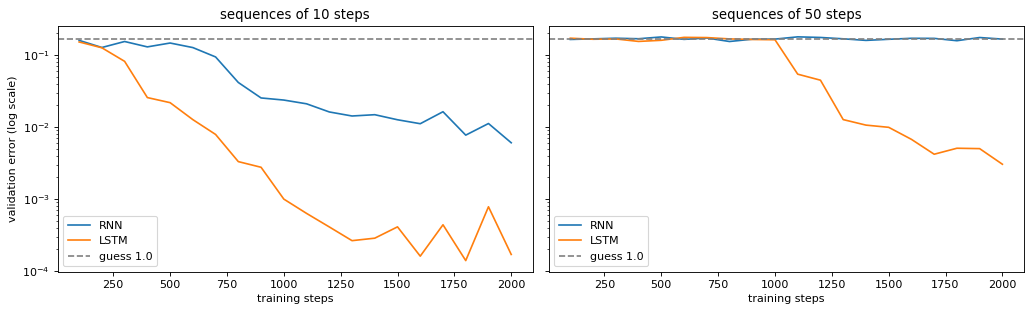

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, T in zip(axes, [10, 50]):
    for kind in ["RNN", "LSTM"]:
        ax.plot(np.arange(1, 21) * 100, runs[(kind, T)][1], label=kind)
    ax.axhline(0.167, color="grey", linestyle="--", label="guess 1.0")
    ax.set_title(f"sequences of {T} steps")
    ax.set_xlabel("training steps")
    ax.set_yscale("log")
    ax.legend()
axes[0].set_ylabel("validation error (log scale)")
plt.tight_layout()
plt.show()

**What we see.** A clean contrast pair:
- With **10 steps**, both networks solve the task: the RNN reaches an error of **0.006** and the LSTM **0.0002**, far below the 0.166 of guessing.
- With **50 steps**, the plain RNN **never** gets off the baseline: its error ends at **0.167**, exactly the error of always answering 1.0. The LSTM sits on the same plateau for a while and then finds the solution, ending at **0.003**.

The plain RNN is not useless; it is limited to **short** memories. The LSTM's curve also shows something typical: a long flat stretch, then a sudden drop when the network discovers how to use its memory.

## 5. Measuring the vanishing gradient

How much does the **first** step of the sequence influence the network's answer, as seen by backpropagation? We compute the gradient of the loss with respect to the input at every time step, for the two networks trained on $T = 50$, and compare its size at the beginning and at the end of the sequence.

RNN: gradient at step 1 / gradient at step 50 = 0.0000
LSTM: gradient at step 1 / gradient at step 50 = 0.6639


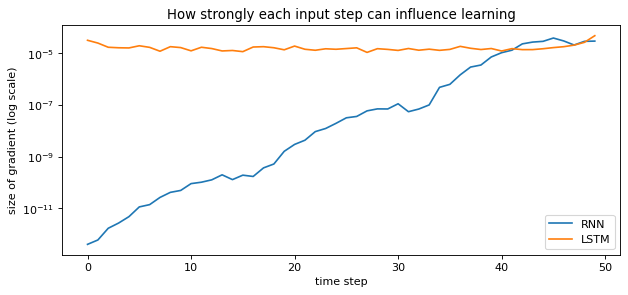

In [6]:
def gradient_over_time(model, T=50, n=500):
    x, y = adding_batch(n, T)
    x.requires_grad_(True)
    F.mse_loss(model(x), y).backward()
    return x.grad.abs().mean(dim=(0, 2)).numpy()

plt.figure(figsize=(9, 3.8))
for kind in ["RNN", "LSTM"]:
    g = gradient_over_time(runs[(kind, 50)][0])
    plt.plot(g, label=kind)
    print(f"{kind}: gradient at step 1 / gradient at step 50 = {g[0] / g[-1]:.4f}")
plt.yscale("log")
plt.xlabel("time step")
plt.ylabel("size of gradient (log scale)")
plt.legend()
plt.title("How strongly each input step can influence learning")
plt.show()

**What we see.** For the trained RNN, the gradient that reaches step 1 is essentially **zero** compared with step 50 (the ratio prints as 0.0000): the error at the end of the sequence has no way to tell the network what to do about the first steps, so it cannot learn to remember them. For the LSTM, the gradient at step 1 is still about **two thirds** (0.66) of the gradient at step 50. On the log scale, the RNN line falls steadily from right to left over many orders of magnitude while the LSTM line stays almost flat. This is the vanishing gradient problem, measured, and the LSTM's cell state is what prevents it.

## ⚠️ Common pitfalls

- **Assuming an LSTM always beats an RNN.** On short dependencies a plain RNN is often just as good, and cheaper (Section 4).
- **Forgetting gradient clipping.** Recurrent networks can also have **exploding** gradients; clipping the gradient norm is a standard safeguard.
- **Using the wrong output.** For a whole-sequence answer, use the state at the **last** step (or a pooled summary), not the first.
- **Comparing networks after too few steps.** LSTMs often stay on a plateau before they suddenly find the solution (look at the curve for $T = 50$). Stopping early would hide this.
- **Feeding very long sequences to any recurrent network.** Even LSTMs struggle beyond a few hundred steps; this limit is what attention and Transformers address (Notebooks 06 and 07).

## ✏️ Exercises

### Exercise 1 (A GRU)
The **GRU** (Cho et al., 2014) simplifies the LSTM to two gates and no separate cell state. Replace `nn.LSTM` with `nn.GRU` in `Reader` and train it on $T = 50$. How does it compare with the LSTM, in error and in number of weights?

In [7]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
class GRUReader(Reader):
    def __init__(self, hidden=64):
        super().__init__("LSTM", hidden)
        self.recurrent = nn.GRU(input_size=2, hidden_size=hidden, batch_first=True)

torch.manual_seed(0)
gru = GRUReader()
opt = torch.optim.Adam(gru.parameters(), lr=2e-3)
for step in range(2000):
    x, y = adding_batch(64, 50)
    loss = F.mse_loss(gru(x), y)
    opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(gru.parameters(), 1.0); opt.step()
xv, yv = adding_batch(1000, 50)
with torch.no_grad():
    print("GRU error:", round(F.mse_loss(gru(xv), yv).item(), 4), "  weights:", count(gru))
```

*The GRU has three quarters of the LSTM's recurrent weights (three blocks of gates instead of four) and usually learns the adding problem as well. In practice the two are close; the GRU is cheaper, the LSTM slightly more flexible.*
</details>

### Exercise 2 (Is it luck?)
Train the RNN and the LSTM on $T = 50$ with seeds 1 and 2 (`train(kind, 50, seed=s)`). Does the LSTM succeed every time, and does the RNN always fail?

In [8]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
for seed in [1, 2]:
    for kind in ["RNN", "LSTM"]:
        _, curve, _ = train(kind, 50, seed=seed)
        print(f"seed {seed}, {kind}: final error {curve[-1]:.4f}")
```

*Results on toy tasks vary with the random start: an LSTM may need more steps on one seed, and a plain RNN occasionally gets lucky. A claim like "the LSTM solves it, the RNN does not" deserves several seeds before it is believed.*
</details>

### Exercise 3 (Look at the forget gate)
PyTorch stores the LSTM's four gate biases in one vector `bias_ih_l0 + bias_hh_l0`, in the order input, **forget**, cell, output, each of length 64. Print the average forget-gate bias of the LSTM trained on $T = 50$. Is it positive (keep memory) or negative (forget)?

In [9]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
lstm = runs[("LSTM", 50)][0].recurrent
bias = (lstm.bias_ih_l0 + lstm.bias_hh_l0).detach()
h = 64
print("input gate bias  :", round(bias[:h].mean().item(), 3))
print("forget gate bias :", round(bias[h:2 * h].mean().item(), 3))
print("output gate bias :", round(bias[3 * h:].mean().item(), 3))
```

*A positive forget bias means the gate starts close to "keep". For tasks with long gaps the network tends to learn to keep its memory, and many practitioners initialise the forget bias to 1 for exactly this reason (Jozefowicz et al., 2015).*
</details>

## 🔑 Key takeaways

- An **RNN** carries a hidden state through time; its gradient is multiplied at every step and tends to **vanish** over long gaps.
- The **LSTM** adds a **cell state** updated by gated **addition**, so information and gradient can pass through many steps unchanged.
- On the **adding problem**, both networks handle short gaps, but only the LSTM learns the 50-step task here.
- Measuring the gradient over time shows the mechanism directly.
- LSTMs dominated sequence modelling until attention let networks look at **every** step directly, the subject of the next two notebooks.

---
**Next:** *Notebook 06: Sequence to Sequence with Attention*, where an encoder LSTM reads a sentence, a decoder LSTM writes another, and attention lets the decoder look back at any word.

---
*© Ioannis Tsioulis. *From Papers to Practice: Landmark Deep Learning Architectures*. Prepared for educational use.*